# 01 · Fundamentos de grafos com Pix

**Objetivo:** revisar os conceitos básicos da teoria dos grafos com um exemplo pequeno de transações Pix e aprender os comandos correspondentes do NetworkX.

**Conceitos:** grafo, vértice, aresta, grafo direcionado, grafo ponderado, multigrafo, lista e matriz de adjacência, densidade, grau, lema do aperto de mãos, caminho, alcançabilidade, conectividade fraca e forte, condensação, ciclo.

**Leitura de apoio:** Diestel, *Graph Theory*, cap. 1; Easley & Kleinberg, *Networks, Crowds, and Markets*, cap. 2.

In [1]:
import networkx as nx
import pandas as pd

from pixfraud.graph import adjacency_matrix, describe, graph_from_csv, graph_from_edges
from pixfraud.visualization import draw_graph

## 1. O que é um grafo

Um grafo $G = (V, E)$ é formado por um conjunto de **vértices** $V$ e um conjunto de **arestas** $E$, cada aresta ligando dois vértices. No projeto: **vértice = conta** e **aresta = Pix**.

Um Pix sai de uma conta e chega a outra, então a aresta tem sentido. Isso é um **grafo direcionado** (ou *dígrafo*): cada aresta é um par ordenado $(u, v)$, lido como "$u$ pagou $v$".

vértices: ['ana', 'bruno', 'carla', 'padaria']
arestas:  [('ana', 'bruno'), ('ana', 'padaria'), ('bruno', 'carla'), ('bruno', 'padaria'), ('carla', 'ana')]


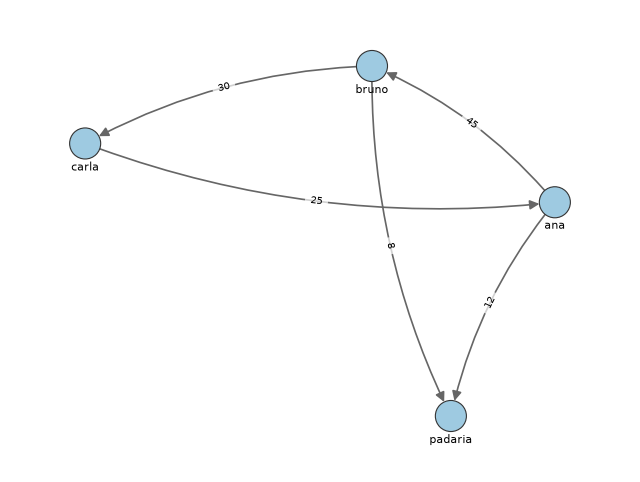

In [2]:
G = graph_from_edges([
    ("ana", "bruno", 45),
    ("bruno", "carla", 30),
    ("carla", "ana", 25),
    ("ana", "padaria", 12.5),
    ("bruno", "padaria", 8),
])
print("vértices:", list(G.nodes))
print("arestas: ", list(G.edges))
draw_graph(G, color_by=None);

O valor de cada Pix fica guardado como **atributo** da aresta (`amount`). Um grafo com números associados às arestas é um **grafo ponderado**.

In [3]:
G["ana"]["bruno"]

{'amount': 45.0, 'count': 1}

### Direcionado × não direcionado

Se ignorarmos o sentido, "ana pagou bruno" e "bruno pagou ana" viram a mesma relação: "ana e bruno transacionam". Isso às vezes é útil, por exemplo para medir se os contatos de uma conta se conhecem entre si (notebook 03). Só que perde a informação de **para onde o dinheiro foi**, central para detectar fraudes.

In [4]:
U = G.to_undirected()
print("direcionado?", G.is_directed(), "|", U.is_directed())
print("arestas sem sentido:", list(U.edges))

direcionado? True | False
arestas sem sentido: [('ana', 'bruno'), ('ana', 'padaria'), ('ana', 'carla'), ('bruno', 'carla'), ('bruno', 'padaria')]


## 2. O exemplo da aula

O arquivo `dados/exemplo_transacoes.csv` tem 20 Pix entre 11 contas: um grupo de amigos, dois comércios e um golpe. Os papéis das contas estão em `dados/exemplo_contas.csv`.

In [5]:
tx = pd.read_csv("dados/exemplo_transacoes.csv")
contas = pd.read_csv("dados/exemplo_contas.csv")
tx

,sender,receiver,amount,timestamp
0,ana,bruno,45.0,2026-03-02 12:10
1,bruno,carla,30.0,2026-03-02 19:40
2,carla,ana,25.0,2026-03-03 08:15
3,ana,padaria,12.5,2026-03-03 07:30
4,bruno,padaria,8.0,2026-03-03 07:45
5,davi,padaria,15.0,2026-03-04 07:20
6,elisa,mercado,230.0,2026-03-04 18:00
7,davi,elisa,60.0,2026-03-04 20:10
8,elisa,davi,60.0,2026-03-05 09:00
9,ana,bruno,20.0,2026-03-05 13:00


### Multigrafo × grafo agregado

Entre o mesmo par de contas pode haver vários Pix (carla pagou `conta_x` duas vezes). Há duas formas de representar isso:

- **multigrafo** (`MultiDiGraph`): uma aresta para cada Pix. As arestas entre o mesmo par são **paralelas**;
- **grafo agregado** (`DiGraph`): uma aresta por par, com o valor somado em `amount` e o número de Pix em `count`.

As métricas do projeto usam o grafo agregado. O multigrafo preserva detalhes como o horário de cada Pix.

In [6]:
M = graph_from_csv("dados/exemplo_transacoes.csv", aggregate=False)
A = graph_from_csv("dados/exemplo_transacoes.csv")
print("multigrafo:", M.number_of_edges(), "arestas")
print("agregado:  ", A.number_of_edges(), "arestas")
print("carla -> conta_x:", A["carla"]["conta_x"])

multigrafo: 20 arestas
agregado:   18 arestas
carla -> conta_x: {'amount': 2700.0, 'count': 2}


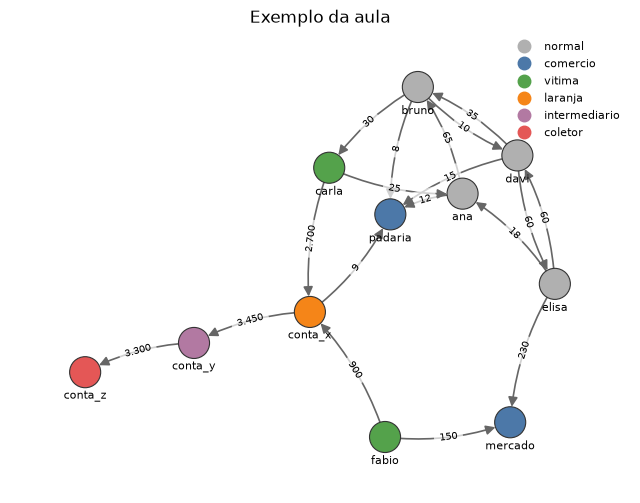

In [7]:
nx.set_node_attributes(A, contas.set_index("account_id")["role"].to_dict(), "role")
draw_graph(A, title="Exemplo da aula");

## 3. Representações: lista e matriz de adjacência

A **lista de adjacência** guarda, para cada vértice, os vizinhos de saída. É assim que o NetworkX armazena o grafo, e é eficiente para grafos **esparsos**, com poucas arestas em relação ao máximo possível. Redes financeiras são esparsas.

In [8]:
for conta, vizinhos in A.adj.items():
    print(f"{conta:8} -> {list(vizinhos)}")

ana      -> ['bruno', 'padaria']
bruno    -> ['carla', 'davi', 'padaria']
padaria  -> []
carla    -> ['ana', 'conta_x']
davi     -> ['bruno', 'elisa', 'padaria']
conta_x  -> ['conta_y', 'padaria']
conta_y  -> ['conta_z']
conta_z  -> []
elisa    -> ['ana', 'davi', 'mercado']
mercado  -> []
fabio    -> ['conta_x', 'mercado']


A **matriz de adjacência** $M$ tem uma linha e uma coluna por vértice: $M_{uv} = 1$ se existe a aresta $u \to v$ (ou o valor transferido, na versão ponderada). Num dígrafo ela **não** é simétrica.

In [9]:
M_adj = adjacency_matrix(A)
M_adj.astype(int)

,ana,bruno,padaria,carla,davi,conta_x,conta_y,conta_z,elisa,mercado,fabio
ana,0,1,1,0,0,0,0,0,0,0,0
bruno,0,0,1,1,1,0,0,0,0,0,0
padaria,0,0,0,0,0,0,0,0,0,0,0
carla,1,0,0,0,0,1,0,0,0,0,0
davi,0,1,1,0,0,0,0,0,1,0,0
conta_x,0,0,1,0,0,0,1,0,0,0,0
conta_y,0,0,0,0,0,0,0,1,0,0,0
conta_z,0,0,0,0,0,0,0,0,0,0,0
elisa,1,0,0,0,1,0,0,0,0,1,0
mercado,0,0,0,0,0,0,0,0,0,0,0


A **densidade** é a fração das arestas possíveis que de fato existem. Num dígrafo simples (sem laços nem arestas paralelas) com $n$ vértices cabem $n(n-1)$ arestas:

$$\text{densidade} = \frac{|E|}{n(n-1)}$$

Com os 2.142 vértices do dataset sintético, a matriz teria ~4,6 milhões de células para ~32 mil arestas. Quase tudo seria zero, e por isso na prática se usa a lista ou matrizes esparsas.

In [10]:
n, m = A.number_of_nodes(), A.number_of_edges()
print(f"densidade = {m} / ({n}·{n - 1}) = {m / (n * (n - 1)):.4f}")
print("nx.density:", round(nx.density(A), 4))

densidade = 18 / (11·10) = 0.1636
nx.density: 0.1636


## 4. Grau

Num dígrafo, cada vértice $v$ tem:

- **grau de entrada** $d^-(v)$: nº de arestas que chegam, ou seja, de quantas contas distintas recebeu;
- **grau de saída** $d^+(v)$: nº de arestas que saem, ou seja, para quantas contas distintas enviou.

Somando os valores das arestas obtém-se a **força** (*strength*): quanto a conta recebeu e quanto enviou.

In [11]:
graus = pd.DataFrame({
    "entrada": dict(A.in_degree()),
    "saída": dict(A.out_degree()),
    "recebeu (R$)": dict(A.in_degree(weight="amount")),
    "enviou (R$)": dict(A.out_degree(weight="amount")),
})
graus.sort_values("recebeu (R$)", ascending=False)

,entrada,saída,recebeu (R$),enviou (R$)
conta_x,2,2,3600.0,3459.0
conta_y,1,1,3450.0,3300.0
conta_z,1,0,3300.0,0.0
mercado,2,0,380.0,0.0
bruno,2,3,100.0,48.0
davi,2,3,70.0,110.0
elisa,1,3,60.0,308.0
padaria,4,0,44.5,0.0
ana,2,2,43.0,77.5
carla,1,2,30.0,2725.0


Repare em `conta_x`: recebeu de só 2 contas, mas repassou quase tudo o que recebeu (R\$ 3.459 de R\$ 3.600). Grau e valores já dão pistas. Por outro lado, `padaria` tem o maior grau de entrada e é legítima. Por isso o projeto combina várias métricas.

### Lema do aperto de mãos

Toda aresta sai de um vértice e chega em outro. Então:

$$\sum_{v} d^-(v) = \sum_{v} d^+(v) = |E|$$

No grafo não direcionado cada aresta é contada nas duas pontas: $\sum_v d(v) = 2|E|$.

Na matriz de adjacência, as somas das **linhas** são os graus de saída e as somas das **colunas**, os de entrada.

In [12]:
print("Σ entrada =", sum(d for _, d in A.in_degree()),
      "| Σ saída =", sum(d for _, d in A.out_degree()),
      "| |E| =", A.number_of_edges())

U = A.to_undirected()
print("não direcionado: Σ grau =", sum(d for _, d in U.degree()), "| 2|E| =", 2 * U.number_of_edges())

print("linhas da matriz = graus de saída?", (M_adj.sum(axis=1) == pd.Series(dict(A.out_degree()))).all())

Σ entrada = 18 | Σ saída = 18 | |E| = 18
não direcionado: Σ grau = 32 | 2|E| = 32
linhas da matriz = graus de saída? True


O grafo não direcionado tem 16 arestas, e não 18: os pares com Pix nos dois sentidos (davi ↔ elisa e bruno ↔ davi) viram uma aresta só.

## 5. Caminhos e alcançabilidade

Um **caminho** é uma sequência de vértices $v_0, v_1, \dots, v_k$ em que cada par consecutivo é ligado por uma aresta no sentido certo. O **comprimento** do caminho é o número de arestas, $k$. Se existe caminho de $u$ para $v$, dizemos que $v$ é **alcançável** a partir de $u$: o dinheiro de $u$ *pode* ter chegado a $v$.

In [13]:
print("fabio alcança conta_z?", nx.has_path(A, "fabio", "conta_z"))
print("caminho mais curto:   ", nx.shortest_path(A, "fabio", "conta_z"))
print("conta_z alcança fabio?", nx.has_path(A, "conta_z", "fabio"))

fabio alcança conta_z? True
caminho mais curto:    ['fabio', 'conta_x', 'conta_y', 'conta_z']
conta_z alcança fabio? False


`nx.descendants` devolve todas as contas alcançáveis a partir de uma conta, ou seja, para onde o dinheiro pode ter ido. `nx.ancestors` devolve todas as contas que a alcançam, ou seja, de onde o dinheiro pode ter vindo.

In [14]:
print("para onde o dinheiro de carla pode ter ido:", sorted(nx.descendants(A, "carla")))
print("de onde o dinheiro de conta_z pode ter vindo:", sorted(nx.ancestors(A, "conta_z")))

para onde o dinheiro de carla pode ter ido: ['ana', 'bruno', 'conta_x', 'conta_y', 'conta_z', 'davi', 'elisa', 'mercado', 'padaria']
de onde o dinheiro de conta_z pode ter vindo: ['ana', 'bruno', 'carla', 'conta_x', 'conta_y', 'davi', 'elisa', 'fabio']


> ⚠️ **O grafo agregado esquece o tempo.** Pelo grafo, o dinheiro de elisa "pode" ter chegado a `conta_z` (elisa → ana → bruno → carla → conta_x → …). Mas elisa só pagou ana em 08/03, dois dias depois do golpe. Um caminho só faz sentido financeiro se os Pix acontecerem em ordem cronológica. Esses são os **caminhos temporais**.
>
> Esse é um ponto importante para a pesquisa: o grafo estático superestima por onde o dinheiro pode ter passado. O exercício 3 explora isso.

## 6. Conectividade

- Um dígrafo é **fracamente conexo** se, ignorando o sentido das arestas, existe caminho entre quaisquer dois vértices.
- É **fortemente conexo** se existe caminho *no sentido das arestas* entre quaisquer dois vértices, de ida e de volta.
- As **componentes fortemente conexas** (CFCs) são os maiores grupos de vértices que se alcançam mutuamente. Numa CFC com mais de um vértice, o dinheiro pode circular e voltar à origem.

In [15]:
print("fracamente conexo?", nx.is_weakly_connected(A))
print("fortemente conexo?", nx.is_strongly_connected(A))
for cfc in sorted(nx.strongly_connected_components(A), key=len, reverse=True):
    print(sorted(cfc))

fracamente conexo? True
fortemente conexo? False
['ana', 'bruno', 'carla', 'davi', 'elisa']
['conta_z']
['conta_y']
['padaria']
['conta_x']
['mercado']
['fabio']


Os amigos formam uma CFC, porque o dinheiro circula entre eles. O golpe forma uma sequência de CFCs de um vértice só: o dinheiro vai e não volta.

A **condensação** troca cada CFC por um único vértice. O resultado é sempre acíclico (um *DAG*, de *directed acyclic graph*) e mostra o fluxo geral do dinheiro.

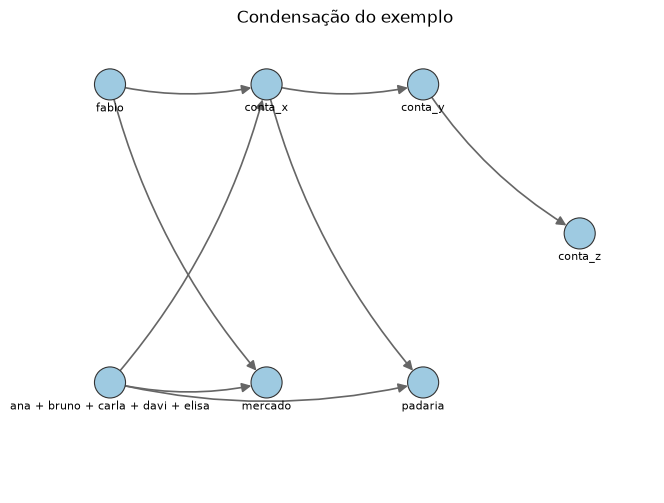

In [16]:
C = nx.condensation(A)
C = nx.relabel_nodes(C, {i: " + ".join(sorted(C.nodes[i]["members"])) for i in C})
draw_graph(C, color_by=None, edge_labels=None, title="Condensação do exemplo");

## 7. Ciclos

Um **ciclo** é um caminho que volta ao vértice inicial. Em finanças, ciclos podem ser legítimos, como amigos dividindo contas. Também podem indicar *round-tripping*: o dinheiro dá voltas para esconder a origem (notebook 04).

In [17]:
for ciclo in nx.simple_cycles(A):
    print(" -> ".join(ciclo + ciclo[:1]))

ana -> bruno -> carla -> ana
ana -> bruno -> davi -> elisa -> ana
davi -> bruno -> davi
davi -> elisa -> davi


## Resumo

`describe` reúne as propriedades vistas neste notebook:

In [18]:
describe(A)

vértices                                11
arestas                                 18
direcionado                           True
multigrafo                           False
densidade                         0.163636
grau médio                        3.272727
laços                                    0
componentes fracamente conexas           1
componentes fortemente conexas           7
reciprocidade                     0.222222
acíclico (DAG)                       False
dtype: object

## Exercícios

As respostas estão em `gabarito.ipynb`. Tente antes de olhar!

1. **Grau.** Qual conta do exemplo tem o maior grau de entrada? E a maior força de entrada (valor recebido)? Por que as respostas são diferentes?
2. **Matriz ponderada.** Monte a matriz de adjacência ponderada (`weight="amount"`) e use as somas de linhas e colunas para descobrir quanto cada conta enviou e recebeu. Confira com `A.out_degree(weight="amount")`.
3. **Caminhos temporais.** Liste as contas que alcançam `conta_x` (`nx.ancestors`). Quais delas podem *de fato* ter mandado dinheiro para `conta_x`, respeitando a ordem cronológica dos Pix? Use o multigrafo `M`, que guarda o horário de cada Pix.
4. **Conectividade.** Remova a aresta `bruno → carla` de uma cópia do grafo (`H = A.copy()` e depois `H.remove_edge(...)`). Quantas componentes fortemente conexas o grafo passa a ter? Por quê?
5. **Densidade.** Qual é o número máximo de arestas de um dígrafo simples com 11 vértices? Confira com a densidade calculada acima.

In [19]:
# seu código aqui